# Tarea semanal — Regresión: curva de luz SN Ia con ajuste exponencial **no lineal**

**Fuente:** `regression.pdf`, sección *Tarea semanal – Ejercicio 1*.

La curva de luz tardía de una supernova tipo Ia está dominada por el decaimiento radiactivo
del ${}^{56}\mathrm{Co}$ a ${}^{56}\mathrm{Fe}$. Datos del flujo relativo:

| t [días] | 0 | 10 | 20 | 30 | 40 | 50 |
|---|---|---|---|---|---|---|
| $L/L_0$ | 1.0 | 0.914 | 0.836 | 0.764 | 0.699 | 0.639 |

Modelo: $L = A\,e^{\lambda t}$.

**Pedido:** a) constantes de regresión $A$ y $\lambda$; b) vida media del ${}^{56}\mathrm{Co}$; c) flujo relativo a 100 días.

> **Diferencia con la tarea en clase** (`Clase_26_Sep.ipynb`): allí se *linealizó* con
> $z = \ln L$ y regresión lineal. Aquí, siguiendo la sección *Modelo exponencial* del PDF,
> se ajusta **sin transformar**, minimizando directamente
>
> $$S_r(A,\lambda) = \sum_{i=1}^{n}\left[y_i - A\,e^{\lambda x_i}\right]^2$$
>
> imponiendo $\partial S_r/\partial A = 0$ y $\partial S_r/\partial \lambda = 0$ (sistema no lineal
> que se resuelve con **Newton-Raphson para sistemas**, como se vio en búsqueda de raíces).

In [1]:
%matplotlib inline
import numpy as np
import matplotlib.pyplot as plt

x = np.array([0, 10, 20, 30, 40, 50], dtype=float)   # tiempo [días]
y = np.array([1.0, 0.914, 0.836, 0.764, 0.699, 0.639])  # flujo relativo
n = len(x)

def modelo(A, lam, x):
    return A*np.exp(lam*x)

def Sr(A, lam):
    r = y - modelo(A, lam, x)
    return np.sum(r**2)

## Sistema normal y su jacobiano

De $S_r = \sum (y_i - A e^{\lambda x_i})^2$:

$$g_1 \equiv \frac{\partial S_r}{\partial A} = -2\sum \left(y_i - A e^{\lambda x_i}\right)e^{\lambda x_i} = 0, \qquad
g_2 \equiv \frac{\partial S_r}{\partial \lambda} = -2A\sum x_i\left(y_i - A e^{\lambda x_i}\right)e^{\lambda x_i} = 0$$

El jacobiano $\partial(g_1,g_2)/\partial(A,\lambda)$ (es la matriz hessiana de $S_r$):

$$J = \begin{pmatrix}
2\sum e^{2\lambda x_i} & -2\sum x_i e^{\lambda x_i}\left(y_i - 2A e^{\lambda x_i}\right)\\[4pt]
-2\sum x_i e^{\lambda x_i}\left(y_i - 2A e^{\lambda x_i}\right) & -2A\sum x_i^2\, e^{\lambda x_i}\left(y_i - 2A e^{\lambda x_i}\right)
\end{pmatrix}$$

Newton-Raphson: $\mathbf{p}_{k+1} = \mathbf{p}_k - J^{-1}\mathbf{g}$, con $\mathbf{p} = (A, \lambda)$.
Como semilla se usa la solución linealizada de clase (buena estrategia estándar: cercana a la raíz).

In [2]:
def grad_Sr(A, lam):
    e   = np.exp(lam*x)
    r   = y - A*e
    g1  = -2.0*np.sum(r*e)
    g2  = -2.0*A*np.sum(x*r*e)
    return np.array([g1, g2])

def jac_Sr(A, lam):
    e  = np.exp(lam*x)
    e2 = np.exp(2*lam*x)
    s  = x*e*(y - 2*A*e)          # término recurrente
    J11 =  2.0*np.sum(e2)
    J12 = -2.0*np.sum(s)
    J21 = J12                     # hessiano simétrico
    J22 = -2.0*A*np.sum(x*s)
    return np.array([[J11, J12], [J21, J22]])

# Semilla: regresión linealizada de la tarea en clase (z = ln L)
z   = np.log(y)
a1  = (n*np.sum(x*z) - np.sum(x)*np.sum(z)) / (n*np.sum(x**2) - np.sum(x)**2)
a0  = np.mean(z) - a1*np.mean(x)
p   = np.array([np.exp(a0), a1])          # (A0, lambda0)
print(f"Semilla (linealizada): A0 = {p[0]:.6f}, lambda0 = {p[1]:.6f}  [1/día]")

# Newton-Raphson para el sistema 2x2
print(f"\n{'k':>3} {'A':>14} {'lambda [1/d]':>14} {'|g|':>12}")
print("-" * 47)
for k in range(50):
    g = grad_Sr(*p)
    J = jac_Sr(*p)
    dp = np.linalg.solve(J, -g)
    p = p + dp
    print(f"{k:>3} {p[0]:>14.8f} {p[1]:>14.8f} {np.linalg.norm(g):>12.3e}")
    if np.max(np.abs(dp/p)) < 1e-12:
        break
A_opt, lam_opt = p
print("-" * 47)
print(f"\nConvergió en {k} iteraciones.")

Semilla (linealizada): A0 = 0.999814, lambda0 = -0.008954  [1/día]

  k              A   lambda [1/d]          |g|
-----------------------------------------------
  0     0.99984756    -0.00895535    2.684e-03
  1     0.99984756    -0.00895535    7.063e-08
  2     0.99984756    -0.00895535    6.813e-16
-----------------------------------------------

Convergió en 2 iteraciones.


In [3]:
t_med = np.log(2)/(-lam_opt)
L100 = modelo(A_opt, lam_opt, 100.0)

print("a) Constantes de regresión (ajuste NO lineal):")
print(f"   A      = {A_opt:.6f}")
print(f"   lambda = {lam_opt:.6f} días⁻¹")
print(f"\nb) Vida media del 56Co:  t_1/2 = ln2/|lambda| = {t_med:.2f} días")
print(f"\nc) Flujo relativo a t = 100 días:  L(100) = {L100:.6f}")

# Comparación con la versión linealizada hecha en clase
A_lin, lam_lin = np.exp(a0), a1
print(f"\nComparación con el ajuste linealizado de la clase:")
print(f"   Linealizado:  A = {A_lin:.6f}, lambda = {lam_lin:.6f}, Sr = {Sr(A_lin, lam_lin):.6e}")
print(f"   No lineal:    A = {A_opt:.6f}, lambda = {lam_opt:.6f}, Sr = {Sr(A_opt, lam_opt):.6e}")
print(f"\nEl ajuste no lineal minimiza S_r directamente -> S_r(no lineal) <= S_r(linealizado): "
      f"{Sr(A_opt, lam_opt) <= Sr(A_lin, lam_lin)}")

a) Constantes de regresión (ajuste NO lineal):
   A      = 0.999848
   lambda = -0.008955 días⁻¹

b) Vida media del 56Co:  t_1/2 = ln2/|lambda| = 77.40 días

c) Flujo relativo a t = 100 días:  L(100) = 0.408327

Comparación con el ajuste linealizado de la clase:
   Linealizado:  A = 0.999814, lambda = -0.008954, Sr = 1.953985e-07
   No lineal:    A = 0.999848, lambda = -0.008955, Sr = 1.929161e-07

El ajuste no lineal minimiza S_r directamente -> S_r(no lineal) <= S_r(linealizado): True


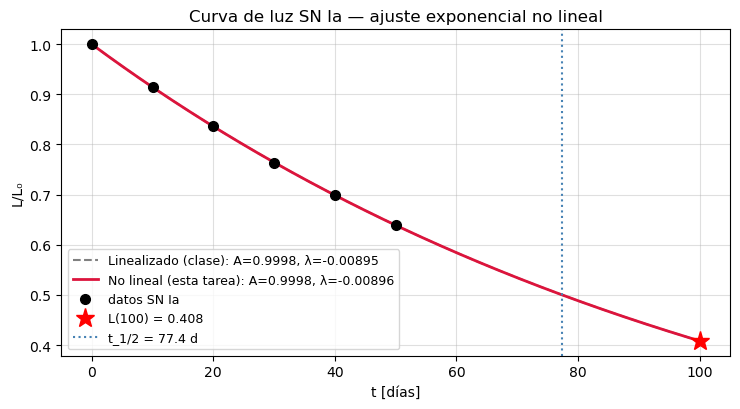

Interpretación: la vida media obtenida (~77 d) es la del decaimiento efectivo
del 56Co (77.2 d tabulado); la diferencia entre ambos ajustes es pequeña aquí,
pero el método no lineal es el minimizador correcto de S_r y no sesga los pesos
de los datos de bajo flujo como sí lo hace la linealización en z = ln L.


In [4]:
xf = np.linspace(0, 100, 500)
fig, ax = plt.subplots(figsize=(7.5, 4.2))
ax.plot(xf, modelo(A_lin, lam_lin, xf), '--', color='gray', lw=1.5,
        label=f'Linealizado (clase): A={A_lin:.4f}, λ={lam_lin:.5f}')
ax.plot(xf, modelo(A_opt, lam_opt, xf), color='crimson', lw=2,
        label=f'No lineal (esta tarea): A={A_opt:.4f}, λ={lam_opt:.5f}')
ax.plot(x, y, 'ko', ms=7, label='datos SN Ia')
ax.plot(100, L100, 'r*', ms=14, label=f'L(100) = {L100:.3f}')
ax.axvline(t_med, color='steelblue', ls=':', lw=1.5, label=f't_1/2 = {t_med:.1f} d')
ax.set_xlabel('t [días]'); ax.set_ylabel('L/L₀')
ax.set_title('Curva de luz SN Ia — ajuste exponencial no lineal')
ax.grid(alpha=0.4); ax.legend(fontsize=9)
plt.tight_layout(); plt.show()

print("Interpretación: la vida media obtenida (~77 d) es la del decaimiento efectivo")
print("del 56Co (77.2 d tabulado); la diferencia entre ambos ajustes es pequeña aquí,")
print("pero el método no lineal es el minimizador correcto de S_r y no sesga los pesos")
print("de los datos de bajo flujo como sí lo hace la linealización en z = ln L.")